# GRAZPEDWRI-DX · Fracture EDA

Pregled validnih YOLO anotacija klase fracture. Slike, pacijenti i objekti imaju zasebne imenioce. Vizuelni izbor služi za inspekciju.

## 1. Obuhvat, učestalost i višestruke anotacije

**Istraživačko pitanje.** Na koliko slika i pacijenata postoji YOLO fracture box?

**Postupak.** Sliku svrstavamo prema stanju anotacionog fajla. Pacijente grupišemo po CSV identifikatoru i beležimo da li bar jedan njihov snimak ima fracture box.

,slike
annotation_status,
fracture_box,13550
no_fracture_box,6777
unknown,0


,pacijenti
bar jedan fracture box,3587
bez zabeleženog fracture box-a,2504


,slike
fracture_boxes,
0,6777
1,9212
2,4137
3,200
4,1


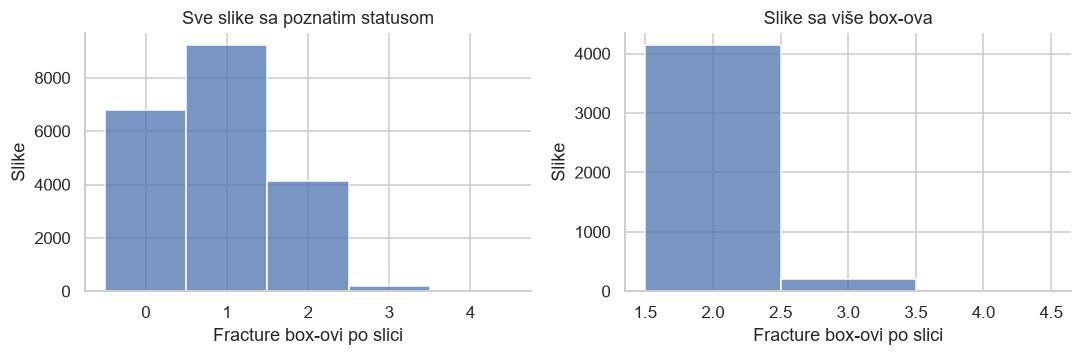

**Numerički sažetak**

,vrednost
CSV_redovi,20327
slike_sa_box,13550
slike_sa_više_box_ova,4338
maksimum_box_ova_na_slici,4
pacijenti,6091
pacijenti_sa_box,3587
objekti,18090


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, Markdown

from wrist_fracture.data.eda import link_annotations, missing_table, source_fingerprint
from wrist_fracture.data.eda_settings import (
    DATASET, SEED, USE_CACHE, analytical_images, load_inputs, stratified_examples,
)
from wrist_fracture.visualization.image_eda import show_gallery_pages

sns.set_theme(style='whitegrid', palette='deep', rc={
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.precision', 4)
root, csv_path, annotation_path, metadata, audit, index, index_issues = load_inputs()
linked = link_annotations(metadata, audit)
images = analytical_images(metadata, audit, index)
expected = set(metadata.filestem.dropna())
indexed = set(index.filestem)
valid_boxes = audit.boxes.loc[audit.boxes.valid]

def summary(**values):
    display(Markdown('**Numerički sažetak**'))
    display(pd.Series(values, name='vrednost').to_frame())

def plot(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)

from wrist_fracture.data.fracture_eda import BOX_KEY, fracture_geometry, measure_fractures
from wrist_fracture.data.image_eda import measure_images

boxes = fracture_geometry(audit.boxes)
status_order = ['fracture_box', 'no_fracture_box', 'unknown']
statuses = linked.annotation_status.value_counts().reindex(status_order, fill_value=0)
patient_flags = linked.assign(
    ima_box=linked.annotation_status.eq('fracture_box'),
    nepoznat=linked.annotation_status.eq('unknown'),
).dropna(subset=['patient_id']).groupby('patient_id')[['ima_box', 'nepoznat']].any()
patient_status = np.select([patient_flags.ima_box, patient_flags.nepoznat],
                           ['bar jedan fracture box', 'nepoznat'], default='bez zabeleženog fracture box-a')
display(statuses.rename('slike').to_frame(),
        pd.Series(patient_status).value_counts().rename('pacijenti').to_frame())
known = linked.loc[linked.annotation_status.ne('unknown')]
multiples = known.loc[known.fracture_boxes.gt(1)]
display(known.fracture_boxes.astype(int).value_counts().sort_index().rename('slike').to_frame())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
sns.histplot(known.fracture_boxes, discrete=True, ax=axes[0])
sns.histplot(multiples.fracture_boxes, discrete=True, ax=axes[1])
for ax, title in zip(axes, ['Sve slike sa poznatim statusom', 'Slike sa više box-ova']):
    ax.set(title=title, xlabel='Fracture box-ovi po slici', ylabel='Slike')
plot(fig)
summary(CSV_redovi=len(linked), slike_sa_box=int(statuses.fracture_box),
        slike_sa_više_box_ova=len(multiples), maksimum_box_ova_na_slici=int(known.fracture_boxes.max()),
        pacijenti=len(patient_flags), pacijenti_sa_box=int(patient_flags.ima_box.sum()), objekti=len(boxes))

<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>

## 2. Veličina i odnosi stranica box-ova

**Istraživačko pitanje.** Kako se raspoređuju relativne mere i stvarne mere u pikselima?

**Postupak.** Normalizovane mere koristimo za sve validne fracture objekte. Pikselne mere dobijamo množenjem izvornim dimenzijama jednoznačno povezanih i dekodiranih slika.

,count,mean,std,min,10%,50%,90%,max
width,18090.0,0.2122,0.0765,0.0440,0.1156,0.2060,0.3159,0.5598
height,18090.0,0.0845,0.0319,0.0249,0.0534,0.0783,0.1209,0.4494
area,18090.0,0.0189,0.0120,0.0018,0.0068,0.0165,0.0329,0.1406
normalized_aspect,18090.0,2.6654,1.0247,0.3513,1.5390,2.5040,4.0209,10.9563


,count,mean,std,min,10%,50%,90%,max
box_width_px,18090.0,118.7094,41.8462,30.0000,69.0001,112.9998,176.9998,300.9997
box_height_px,18090.0,83.7486,31.0950,28.0001,54.0003,77.2038,118.9998,421.9997
box_area_px2,18090.0,10561.9098,6810.2693,1333.0078,4079.9893,8778.0445,19203.2291,78792.1078
pixel_aspect,18090.0,1.4798,0.4731,0.1875,0.9538,1.4151,2.1111,4.7778


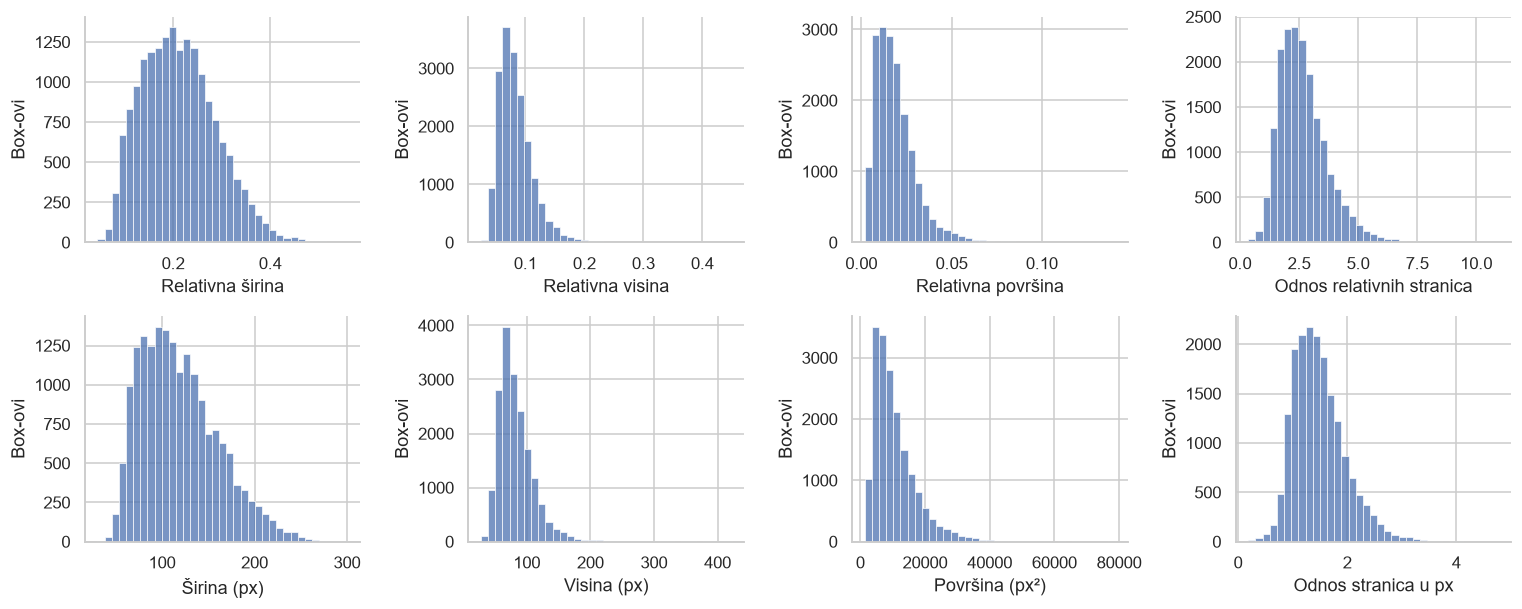

**Numerički sažetak**

,vrednost
normalizovani_box_ovi,18090.000
pikselni_box_ovi,18090.000
bez_dimenzija,0.000
medijana_površine_pct,1.648
medijana_površine_px2,8778.040


In [2]:
dimensions, technical_issues, image_state = measure_images(
    images, limit=None, seed=SEED, hashes=False,
    cache_dir=root / 'results/cache/image_eda' if USE_CACHE else None, context={'dataset': DATASET})
pixels = boxes.merge(dimensions[['filestem', 'width_px', 'height_px']], on='filestem', validate='many_to_one')
pixels['box_width_px'] = pixels.width * pixels.width_px
pixels['box_height_px'] = pixels.height * pixels.height_px
pixels['box_area_px2'] = pixels.box_width_px * pixels.box_height_px
pixels['pixel_aspect'] = pixels.box_width_px / pixels.box_height_px
norm_cols = ['width', 'height', 'area', 'normalized_aspect']
px_cols = ['box_width_px', 'box_height_px', 'box_area_px2', 'pixel_aspect']
display(boxes[norm_cols].describe(percentiles=[.1, .5, .9]).T,
        pixels[px_cols].describe(percentiles=[.1, .5, .9]).T)
fig, axes = plt.subplots(2, 4, figsize=(14, 5.7))
for ax, table, col, label in zip(axes.flat, [boxes]*4 + [pixels]*4, norm_cols + px_cols,
        ['Relativna širina', 'Relativna visina', 'Relativna površina', 'Odnos relativnih stranica',
         'Širina (px)', 'Visina (px)', 'Površina (px²)', 'Odnos stranica u px']):
    sns.histplot(table[col], bins=35, ax=ax)
    ax.set(xlabel=label, ylabel='Box-ovi')
plot(fig)
summary(normalizovani_box_ovi=len(boxes), pikselni_box_ovi=len(pixels),
        bez_dimenzija=len(boxes)-len(pixels),
        medijana_površine_pct=round(100 * boxes.area.median(), 3),
        medijana_površine_px2=round(pixels.box_area_px2.median(), 2))

<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>

## 3. Pozicija preloma i poređenje po projekciji

**Istraživačko pitanje.** Gde su centri box-ova i koje razlike postoje između projekcija?

**Postupak.** Centri su u normalizovanim koordinatama sa početkom gore levo. Za svaku projekciju prikazujemo broj objekata i slika i medijane. Rastojanje od ivice je minimum relativnih margina box-a.

,objekti,slike,pacijenti,medijana_površine,medijana_cx,medijana_cy,medijana_margine,pikselni_box_ovi,medijana_px2
projection,,,,,,,,,
1,10182,6553,3175,0.0151,0.5109,0.5323,0.2683,10182,8549.5034
2,7794,6924,3481,0.0181,0.5011,0.5163,0.3127,7794,9072.0065
3,114,73,64,0.0137,0.4993,0.5342,0.3121,114,7327.0259


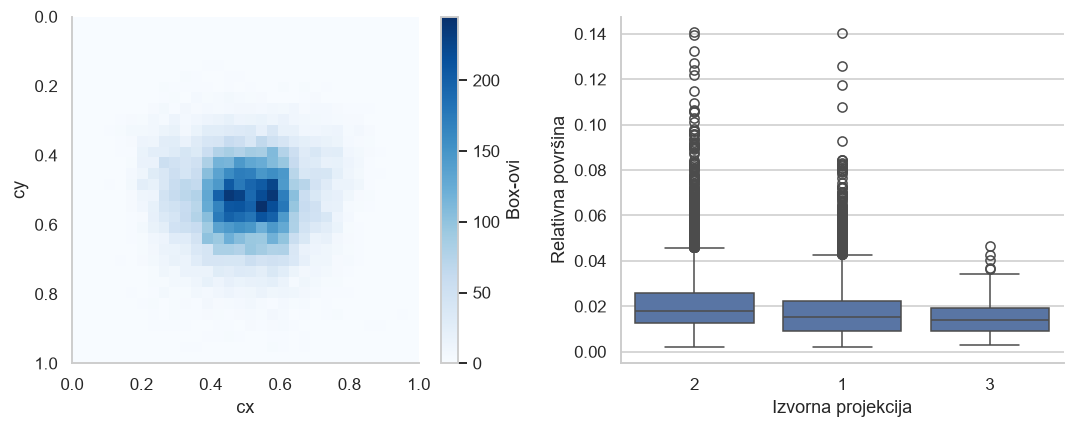

**Numerički sažetak**

,vrednost
objekti,18090.0000
najmanja_grupa_box_ova,114.0000
medijana_cx,0.5040
medijana_cy,0.5246


In [3]:
meta_cols = ['filestem', 'projection', 'laterality', 'patient_id']
unique_meta = linked.loc[~linked.annotation_state.isin(['invalid_identifier', 'ambiguous_metadata']), meta_cols]
spatial = boxes.merge(unique_meta, on='filestem', how='left', validate='many_to_one')
by_projection = spatial.groupby('projection', dropna=False).agg(
    objekti=('line', 'size'), slike=('filestem', 'nunique'), pacijenti=('patient_id', 'nunique'),
    medijana_površine=('area', 'median'), medijana_cx=('cx', 'median'), medijana_cy=('cy', 'median'),
    medijana_margine=('edge_distance', 'median'))
group_pixels = pixels.merge(unique_meta[['filestem', 'projection']], on='filestem',
                            how='left', validate='many_to_one').groupby('projection', dropna=False)
display(by_projection.join(group_pixels.box_area_px2.agg(pikselni_box_ovi='count', medijana_px2='median')))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
hist = axes[0].hist2d(spatial.cx, spatial.cy, bins=32, range=[[0, 1], [0, 1]], cmap='Blues')
fig.colorbar(hist[3], ax=axes[0], label='Box-ovi')
axes[0].set(xlabel='cx', ylabel='cy', ylim=(1,0), aspect='equal')
plot_data = spatial.assign(projekcija=spatial.projection.astype('string').fillna('nedostaje'))
sns.boxplot(data=plot_data, x='projekcija', y='area', ax=axes[1])
axes[1].set(xlabel='Izvorna projekcija', ylabel='Relativna površina')
plot(fig)
summary(objekti=len(spatial), najmanja_grupa_box_ova=int(by_projection.objekti.min()),
        medijana_cx=round(boxes.cx.median(), 4), medijana_cy=round(boxes.cy.median(), 4))

<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>

## 4. Lokalni kontrast u box-u i neposrednoj okolini

**Istraživačko pitanje.** Kako se raspon intenziteta razlikuje unutar i oko box-a?

**Postupak.** Merimo P95–P5 u izvornim DN jedinicama unutar box-a i u okolnom prstenu. Floor/ceil ivice uključuju presečene piksele. Prsten proširuje svaku stranu za 25% odgovarajuće dimenzije box-a, najmanje jedan piksel, i ograničen je ivicama slike. Drugi box-ovi mogu se naći u prstenu. Prazan prsten se evidentira.

,box-ovi
contrast_status,
izmereno,18090


,count,mean,std,min,25%,50%,75%,max
inside_n,18090.0,10763.1774,6870.7720,1452.0,5900.0000,8976.0,13640.00,79391.0
ring_n,18090.0,13590.5005,8584.4555,1782.0,7482.0000,11386.0,17206.00,98604.0
inside_p95_p05_dn,18090.0,15215.3494,5159.0610,3953.0,11450.9375,14340.0,17876.60,58020.3
ring_p95_p05_dn,18090.0,17378.0121,5535.0254,4145.0,13546.6500,16244.0,20096.75,53959.0
abs_median_gap_dn,18090.0,6443.5485,3654.2002,0.0,3799.2500,6178.0,8834.00,34093.0


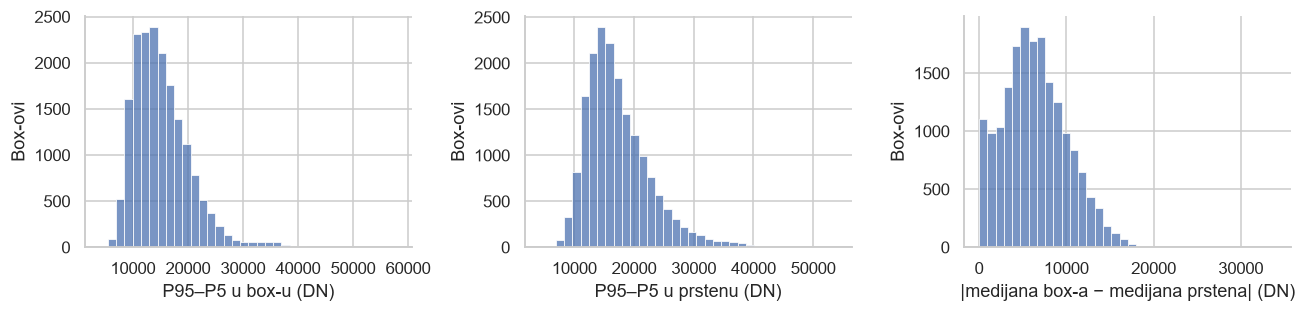

**Numerički sažetak**

,vrednost
ciljani_box_ovi,18090.0
izmeren_box,18090.0
izmeren_prsten,18090.0
oba_izmerena,18090.0
medijana_kontrasta_box_DN,14340.0
medijana_kontrasta_prstena_DN,16244.0


In [4]:
contrast, contrast_state = measure_fractures(
    images, boxes, cache_dir=root / 'results/cache/fracture_eda' if USE_CACHE else None)
contrast_cols = ['inside_p95_p05_dn', 'ring_p95_p05_dn', 'abs_median_gap_dn']
display(contrast.contrast_status.value_counts(dropna=False).rename('box-ovi').to_frame(),
        contrast[['inside_n', 'ring_n', *contrast_cols]].describe().T)
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col, label in zip(axes, contrast_cols, ['P95–P5 u box-u', 'P95–P5 u prstenu', '|medijana box-a − medijana prstena|']):
    sns.histplot(contrast[col], bins=36, ax=ax)
    ax.set(xlabel=f'{label} (DN)', ylabel='Box-ovi')
plot(fig)
summary(ciljani_box_ovi=len(contrast), izmeren_box=int(contrast.inside_p95_p05_dn.count()),
        izmeren_prsten=int(contrast.ring_p95_p05_dn.count()),
        oba_izmerena=int(contrast.contrast_status.eq('izmereno').sum()),
        medijana_kontrasta_box_DN=round(contrast.inside_p95_p05_dn.median(), 2),
        medijana_kontrasta_prstena_DN=round(contrast.ring_p95_p05_dn.median(), 2))

<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>

## 5. Slike bez fracture box-a i slaganje sa CSV-om

**Istraživačko pitanje.** Šta sadrže anotacije bez fracture box-a i kako se statusi porede sa fracture_visible?

**Postupak.** Validne fajlove bez fracture box-a delimo na prazne i one sa drugim klasama. Nepoznat status ostaje zaseban. Prazan fracture_visible je neupisana vrednost. Poređenje opisuje zapise i njihove veze.

,slike
tip_fajla,
sadrži druge klase,6762
prazan,15


annotation_status,fracture_box,no_fracture_box,unknown
fracture_visible,,,
1.0,13550,0,0
neupisano,0,6777,0


,slike,uzrast_n,medijana_uzrasta
annotation_status,,,
fracture_box,13550,13550,10.5
no_fracture_box,6777,6777,12.3


projection,1,2,3
annotation_status,,,
fracture_box,6553,6924,73
no_fracture_box,3533,3224,20


device_manufacturer,Agfa,Siemens
annotation_status,,
fracture_box,74,13476
no_fracture_box,38,6739


laterality,L,R
annotation_status,,
fracture_box,7802,5748
no_fracture_box,3333,3444


aspect_ratio         contrast_fullscale        
                         count  median              count  median
annotation_status                                                
fracture_box             13550  0.5592              13550  0.7073
no_fracture_box           6777  0.5523               6777  0.7260

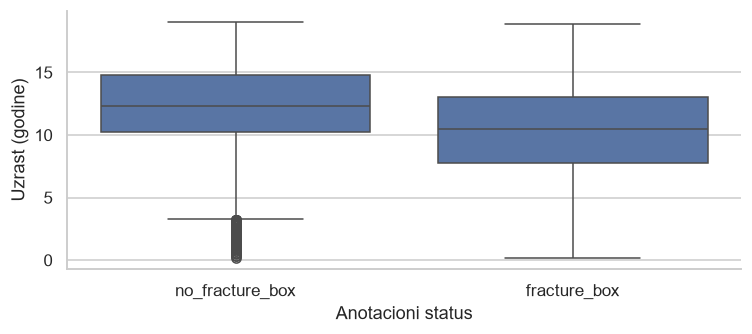

**Numerički sažetak**

,vrednost
bez_box,6777
prazne_anotacije,15
sadrže_druge_klase,6762
nepoznat_status,0
fracture_visible_1_bez_box,0
neupisan_fracture_visible_sa_box,0


In [5]:
without = linked.loc[linked.annotation_status.eq('no_fracture_box')].copy()
without['tip_fajla'] = np.where(without.annotation_state.eq('empty'), 'prazan', 'sadrži druge klase')
recorded = linked.fracture_visible.astype('string').fillna('neupisano')
agreement = pd.crosstab(recorded, linked.annotation_status, dropna=False).reindex(columns=status_order, fill_value=0)
comparison = known.groupby('annotation_status').age.agg(slike='size', uzrast_n='count', medijana_uzrasta='median')
technical = known[['filestem','annotation_status']].merge(
    dimensions.reindex(columns=['filestem','aspect_ratio','contrast_fullscale']), on='filestem', validate='one_to_one')
display(without.tip_fajla.value_counts().rename('slike').to_frame(), agreement, comparison)
display(pd.crosstab(known.annotation_status, known.projection, dropna=False),
        pd.crosstab(known.annotation_status, known.device_manufacturer, dropna=False),
        pd.crosstab(known.annotation_status, known.laterality, dropna=False),
        technical.groupby('annotation_status')[['aspect_ratio','contrast_fullscale']].agg(['count','median']))
fig, ax = plt.subplots(figsize=(7, 3.2))
sns.boxplot(data=known, x='annotation_status', y='age', ax=ax)
ax.set(xlabel='Anotacioni status', ylabel='Uzrast (godine)')
plot(fig)
summary(bez_box=len(without), prazne_anotacije=int(without.tip_fajla.eq('prazan').sum()),
        sadrže_druge_klase=int(without.tip_fajla.eq('sadrži druge klase').sum()),
        nepoznat_status=int(statuses.unknown),
        fracture_visible_1_bez_box=int((linked.fracture_visible.eq(1) & linked.annotation_status.eq('no_fracture_box')).sum()),
        neupisan_fracture_visible_sa_box=int((linked.fracture_visible.isna() & linked.annotation_status.eq('fracture_box')).sum()))

<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>

## 6. Vizuelna provera i kandidati za teške slučajeve

**Istraživačko pitanje.** Kako izgledaju tipični i rubni primeri kada ucrtamo originalne box-ove?

**Postupak.** Tipične primere biramo po tercilima relativne površine najvećeg box-a po slici i dva položajna stratuma određena medijanom minimalne margine. Ciljano biramo ekstreme i višestruke anotacije. U prikazu svih klasa boja i naziv identifikuju originalnu klasu.

,slike,min,max
veličina,,,
tercil 1,4517,0.0022,0.0161
tercil 2,4516,0.0161,0.0239
tercil 3,4517,0.0239,0.1406


,filestem,projection,reason
0,0709_1088662437_01_WRI-L2_M011,2,veličina=tercil 1 | položaj=manja margina
1,0160_0598179343_01_WRI-L2_F009,2,veličina=tercil 1 | položaj=veća margina
2,4377_0723572546_01_WRI-L1_M017,1,veličina=tercil 2 | položaj=manja margina
3,2854_0895306148_04_WRI-R2_M007,2,veličina=tercil 2 | položaj=veća margina
4,1324_0598047414_02_WRI-L1_M013,1,veličina=tercil 3 | položaj=manja margina
5,2747_0550052702_01_WRI-L2_F003,2,veličina=tercil 3 | položaj=veća margina


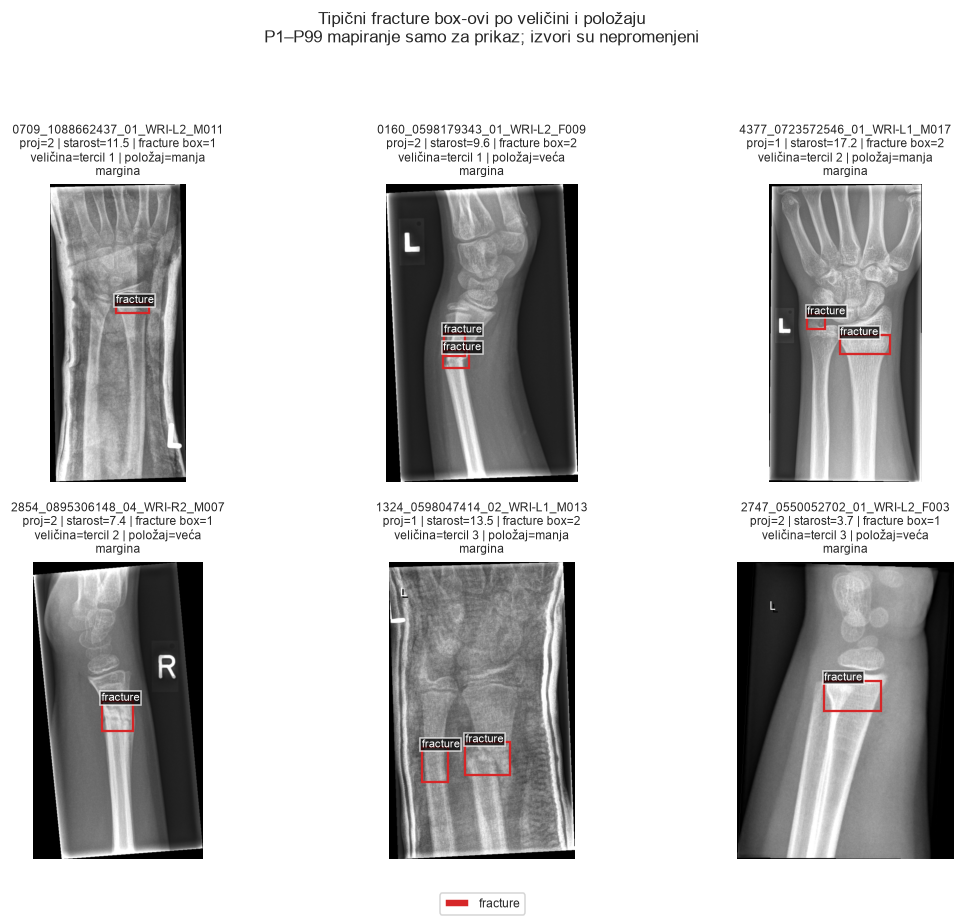

,filestem,projection,reason
0,0545_0524012898_01_WRI-R1_M012,1,projection=1 | tip=druge klase
1,1411_0517013711_01_WRI-L1_F017,1,projection=1 | tip=prazan
2,2471_0562672423_01_WRI-R2_M012,2,projection=2 | tip=druge klase
3,5249_0719897830_01_WRI-L2_F017,2,projection=2 | tip=prazan
4,0224_0777801043_01_WRI-R3_F003,3,projection=3 | tip=druge klase


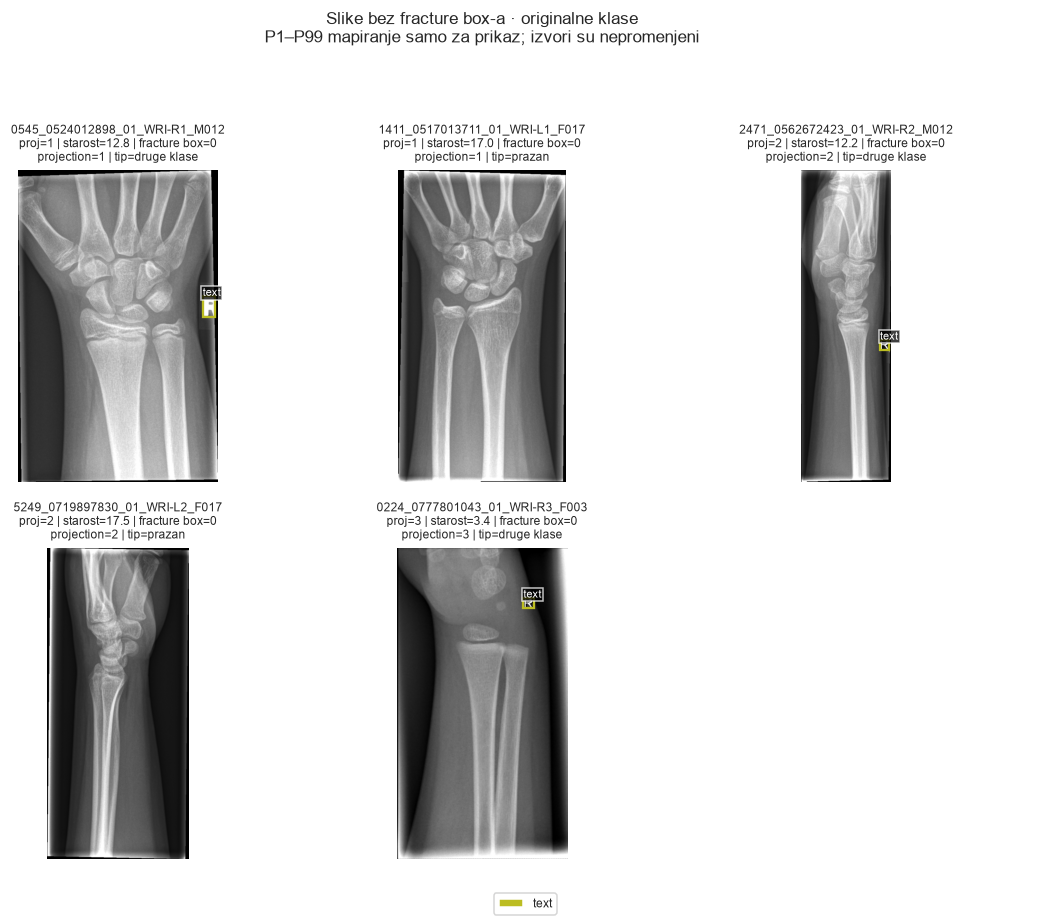

,filestem,projection,reason
0,1775_0372115963_02_WRI-L1_M014,1,Najmanji box · red 6 (0.001843)
1,4692_0834721995_05_WRI-R2_M012,2,Najveći box · red 2 (0.1406)
2,1197_1149393952_01_WRI-R2_M015,2,Box najbliži ivici · red 1 (0)
3,4969_0205523015_02_WRI-L2_F010,2,Najniži kontrast u box-u · red 1 (3953)
4,1197_1149393952_01_WRI-R2_M015,2,Najviši kontrast u box-u · red 1 (5.802e+04)
5,5196_1017000975_01_WRI-L1_M014,1,Najviše fracture box-ova na slici


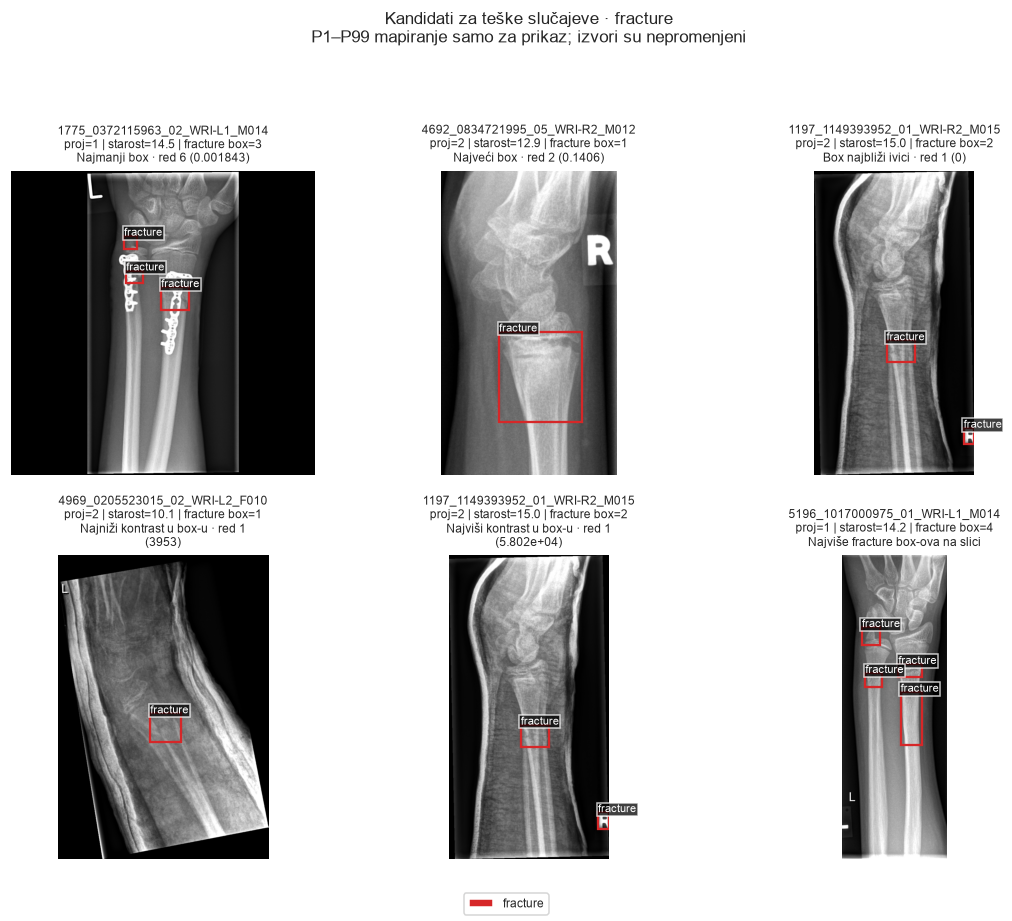

**Numerički sažetak**

,vrednost
stratifikovani_sa_box,6
stratifikovani_bez_box,5
ciljani,6
jedinstvene_slike,16
seed,42


In [6]:
gallery_images = images.loc[images.filestem.isin(dimensions.filestem)]
available_boxes = boxes.loc[boxes.filestem.isin(gallery_images.filestem)].merge(
    contrast, on=BOX_KEY, validate='one_to_one')
typical_boxes = available_boxes.sort_values(['filestem','area','member','line'],
                                          ascending=[True,False,True,True]).drop_duplicates('filestem')
typical_boxes = typical_boxes.assign(
    veličina=pd.qcut(typical_boxes.area, q=3, labels=False, duplicates='drop')
        .map({0: 'tercil 1', 1: 'tercil 2', 2: 'tercil 3'}),
    položaj=np.where(typical_boxes.edge_distance.le(typical_boxes.edge_distance.median()),
                     'manja margina', 'veća margina'))
display(typical_boxes.groupby('veličina', dropna=False).area.agg(slike='size', min='min', max='max'))
typical_pool = gallery_images.merge(typical_boxes[['filestem','veličina','položaj']], on='filestem', validate='one_to_one')
typical = stratified_examples(typical_pool, ['veličina', 'položaj'])
no_box_pool = gallery_images.loc[gallery_images.annotation_status.eq('no_fracture_box')].copy()
no_box_pool['tip'] = np.where(no_box_pool.annotation_state.eq('empty'), 'prazan', 'druge klase')
without_examples = stratified_examples(no_box_pool, ['projection', 'tip'])
candidates = []
for col, high, label in [
    ('area', False, 'Najmanji box'), ('area', True, 'Najveći box'),
    ('edge_distance', False, 'Box najbliži ivici'),
    ('inside_p95_p05_dn', False, 'Najniži kontrast u box-u'),
    ('inside_p95_p05_dn', True, 'Najviši kontrast u box-u'),
]:
    ordered = available_boxes.dropna(subset=[col]).sort_values([col, *BOX_KEY])
    if not ordered.empty:
        box = ordered.iloc[-1 if high else 0]
        candidates.append(gallery_images.loc[gallery_images.filestem.eq(box.filestem)].assign(
            reason=f'{label} · red {box.line} ({box[col]:.4g})'))
multiple_example = gallery_images.loc[gallery_images.fracture_boxes.gt(1)].sort_values(
    ['fracture_boxes', 'image_key'], ascending=[False,True]).head(1)
candidates.append(multiple_example.assign(reason='Najviše fracture box-ova na slici'))
targeted = pd.concat(candidates, ignore_index=True)
for selection, title, overlay in [
    (typical, 'Tipični fracture box-ovi po veličini i položaju', 'fracture'),
    (without_examples, 'Slike bez fracture box-a · originalne klase', 'all'),
    (targeted, 'Kandidati za teške slučajeve · fracture', 'fracture'),
]:
    display(selection[['filestem','projection','reason']])
    show_gallery_pages(selection, audit.boxes, audit.classes, title=title, overlay=overlay)
selection = pd.concat([typical.assign(izbor='stratifikovan sa box-om'),
                       without_examples.assign(izbor='stratifikovan bez box-a'),
                       targeted.assign(izbor='ciljan')])
selection_dir = root / 'results/eda_review'
selection_dir.mkdir(parents=True, exist_ok=True)
selection.assign(seed=SEED, potpis=contrast_state['signature'], skup=DATASET)[
    ['filestem','member','izbor','reason','seed','potpis','skup']
].to_csv(selection_dir / 'fracture_gallery_selection.csv', index=False, encoding='utf-8-sig')
summary(stratifikovani_sa_box=len(typical), stratifikovani_bez_box=len(without_examples), ciljani=len(targeted),
        jedinstvene_slike=selection.filestem.nunique(), seed=SEED)

<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>

## 7. Integritet fracture anotacija

**Istraživačko pitanje.** Koje anotacije zahtevaju dodatnu proveru formata ili povezivanja?

**Postupak.** YOLO parser proverava broj polja, mapu klase, konačne vrednosti, pozitivne dimenzije i normalizovane ivice sa tolerancijom 1e-6 za zaokruživanje. Geometrija i galerije koriste originalne validne redove.

In [7]:
fracture_id = next(key for key, name in audit.classes.items() if name == 'fracture')
edges = pd.DataFrame({
    'levo': boxes.cx-boxes.width/2, 'vrh': boxes.cy-boxes.height/2,
    'desno': boxes.cx+boxes.width/2, 'dno': boxes.cy+boxes.height/2})
outside = (edges[['levo','vrh']].lt(-1e-6).any(axis=1)
           | edges[['desno','dno']].gt(1+1e-6).any(axis=1))
repeat = boxes.duplicated(['filestem','cx','cy','width','height'], keep=False)
display(linked.annotation_state.value_counts().rename('CSV redovi').to_frame(),
        audit.issues.head(12), boxes.loc[repeat, BOX_KEY].head(12))
summary(fracture_class_id=fracture_id, validni_fracture_box_ovi=len(boxes),
        YOLO_nevalidni_redovi=int(audit.files.invalid_rows.sum()),
        provera_ivica_van_tolerancije=int(outside.sum()), identična_geometrija_unutar_slike=int(repeat.sum()),
        fracture_box_ovi_bez_dekodiranih_dimenzija=len(boxes)-len(pixels))

,CSV redovi
annotation_state,
valid,20312
empty,15


,filestem,member,line,issue,raw


,filestem,member,line


**Numerički sažetak**

,vrednost
fracture_class_id,3
validni_fracture_box_ovi,18090
YOLO_nevalidni_redovi,0
provera_ivica_van_tolerancije,0
identična_geometrija_unutar_slike,0
fracture_box_ovi_bez_dekodiranih_dimenzija,0


<h4 style="color:#c00000">MESTO ZA LIČNI ZAKLJUČAK</h4>